# Лабораторная работа №7. Кластеризация данных

**Датасет:** `load_wine` из `sklearn.datasets` (178 объектов, 13 числовых признаков, 3 истинных класса).

Истинные метки **исключаются из обучения** и используются только для внешней проверки качества кластеризации (ARI, NMI).

**План:**
1. Импорт библиотек и настройка
2. Загрузка данных
3. EDA: пропуски и распределения
4. Обработка выбросов (IQR-клиппинг)
5. Стандартизация
6. Понижение размерности (PCA + t-SNE)
7. K-means (elbow + silhouette)
8. Иерархическая кластеризация (дендрограмма)
9. DBSCAN (k-distance graph + перебор параметров)
10. Сводное сравнение метрик
11. Визуализация кластеров
12. Выводы

In [ ]:
# === Ячейка 1. Импорты и настройка ===
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
    confusion_matrix
)

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist

# Глобальные настройки
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.max_columns", 20)

# Версии — для воспроизводимости отчёта
import sklearn, scipy
print(f"numpy   : {np.__version__}")
print(f"pandas  : {pd.__version__}")
print(f"sklearn : {sklearn.__version__}")
print(f"scipy   : {scipy.__version__}")
print("Окружение настроено, random_state =", RANDOM_STATE)

numpy   : 2.4.6
pandas  : 2.2.3
sklearn : 1.6.1
scipy   : 1.16.3
Окружение настроено, random_state = 42


## 2. Загрузка данных

Используем встроенный датасет **Wine** из `sklearn.datasets`:
- 178 объектов, 13 числовых химических признаков (алкоголь, магний, фенолы и т.д.);
- 3 истинных класса вин (сорта);

Истинные метки `y_true` **сохраняем отдельно** и не подаём в обучение кластеризаторов — они нужны только для внешней оценки качества (ARI, NMI).

In [ ]:
# === Ячейка 2. Загрузка датасета ===
wine = load_wine()

# Признаки — DataFrame для удобства
X = pd.DataFrame(wine.data, columns=wine.feature_names)

# Истинные метки — только для внешней проверки, в обучении не участвуют
y_true = pd.Series(wine.target, name="target")

print("Форма X         :", X.shape)
print("Признаки        :", list(X.columns))
print("\nРаспределение истинных классов (для справки):")
print(y_true.value_counts().sort_index().to_string())

print("\nПервые 5 строк:")
display(X.head())

print("\nОписательные статистики:")
display(X.describe().T)

Форма X         : (178, 13)
Признаки        : ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Распределение истинных классов (для справки):
target
0    59
1    71
2    48

Первые 5 строк:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.230,1.710,2.430,15.600,127.000,2.800,3.060,0.280,2.290,5.640,1.040,3.920,1065.000
1,13.200,1.780,2.140,11.200,100.000,2.650,2.760,0.260,1.280,4.380,1.050,3.400,1050.000
2,13.160,2.360,2.670,18.600,101.000,2.800,3.240,0.300,2.810,5.680,1.030,3.170,1185.000
3,14.370,1.950,2.500,16.800,113.000,3.850,3.490,0.240,2.180,7.800,0.860,3.450,1480.000
4,13.240,2.590,2.870,21.000,118.000,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735.000



Описательные статистики:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.000,13.001,0.812,11.030,12.362,13.050,13.678,14.830
malic_acid,178.000,2.336,1.117,0.740,1.603,1.865,3.083,5.800
ash,178.000,2.367,0.274,1.360,2.210,2.360,2.558,3.230
alcalinity_of_ash,178.000,19.495,3.340,10.600,17.200,19.500,21.500,30.000
magnesium,178.000,99.742,14.282,70.000,88.000,98.000,107.000,162.000
total_phenols,178.000,2.295,0.626,0.980,1.742,2.355,2.800,3.880
flavanoids,178.000,2.029,0.999,0.340,1.205,2.135,2.875,5.080
nonflavanoid_phenols,178.000,0.362,0.124,0.130,0.270,0.340,0.438,0.660
proanthocyanins,178.000,1.591,0.572,0.410,1.250,1.555,1.950,3.580
color_intensity,178.000,5.058,2.318,1.280,3.220,4.690,6.200,13.000


## 3. EDA: проверка пропусков и распределений

Проверяем:
1. **Наличие пропусков** — `NaN` в датасете Wine отсутствуют, но проверку делаем формально (требование п.2 задания).
2. **Распределения признаков** — визуально оцениваем асимметрию и наличие выбросов, которые повлияют на K-means и DBSCAN.
3. **Boxplot по всем признакам** (после временной стандартизации только для отображения — чтобы масштабы были сопоставимы) — так сразу видны выбросы.

Пропуски по признакам:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0

Всего пропусков: 0


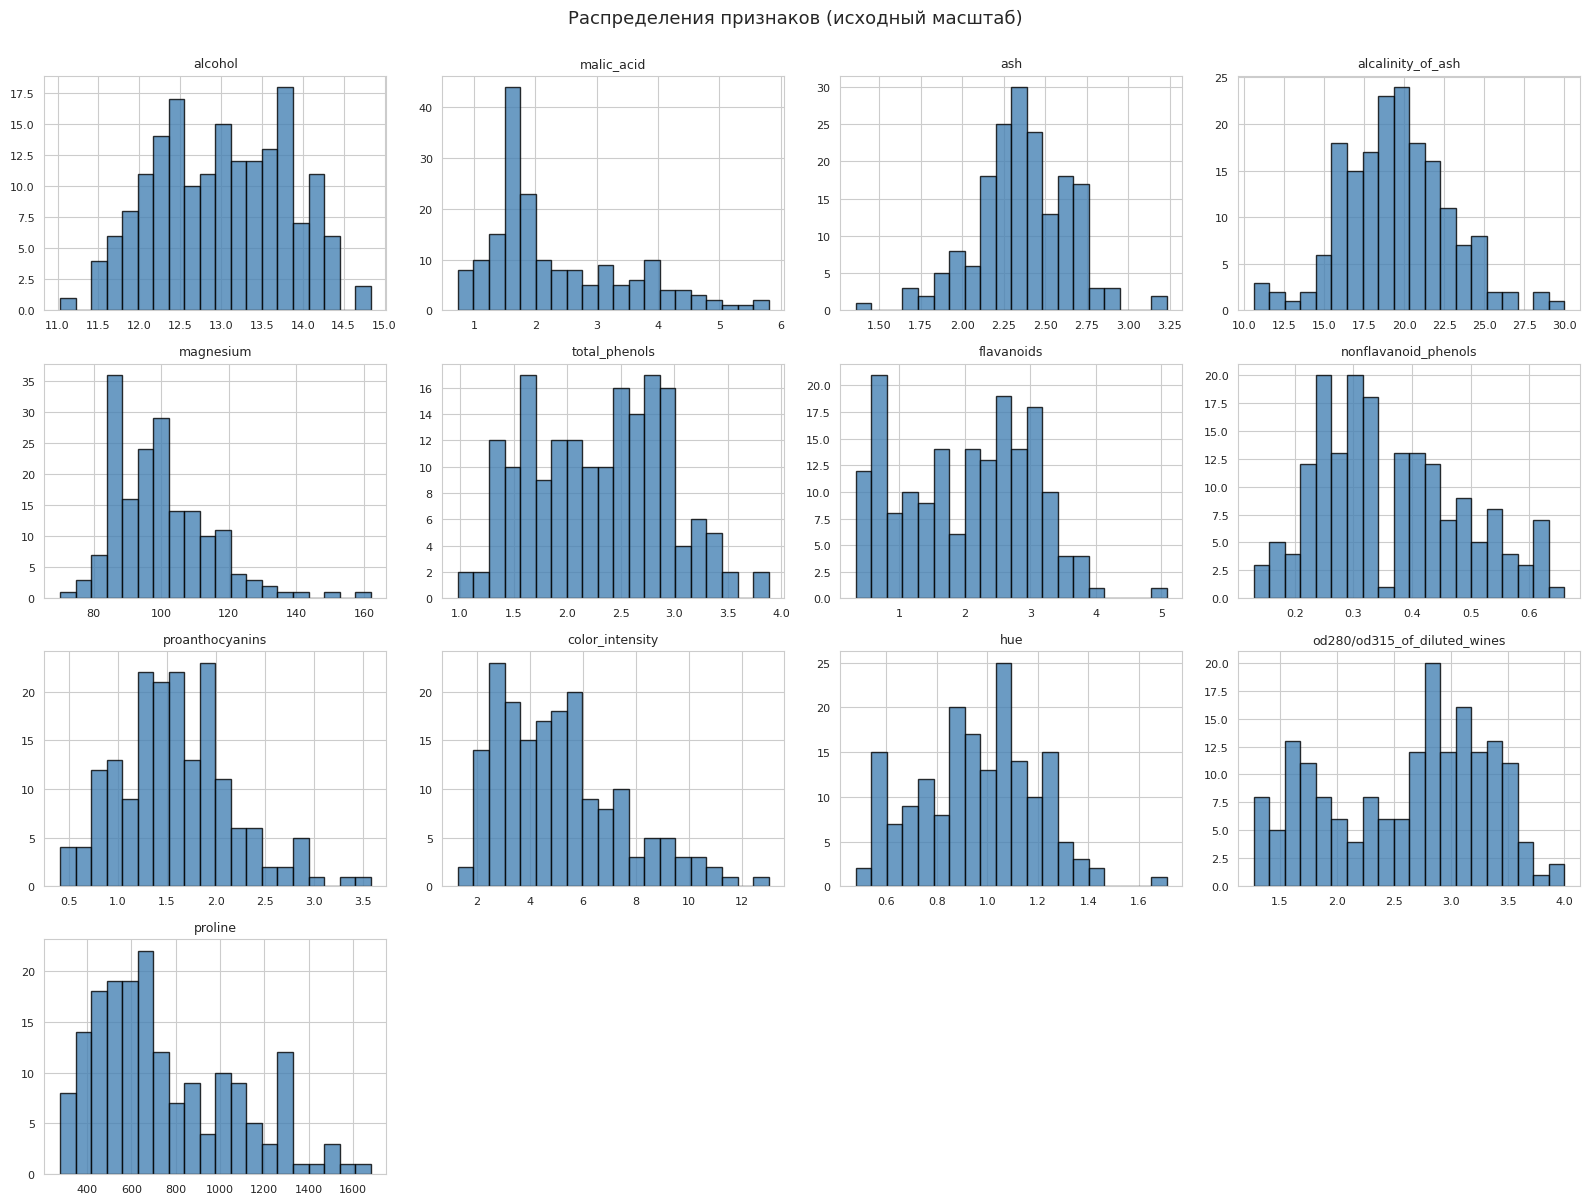

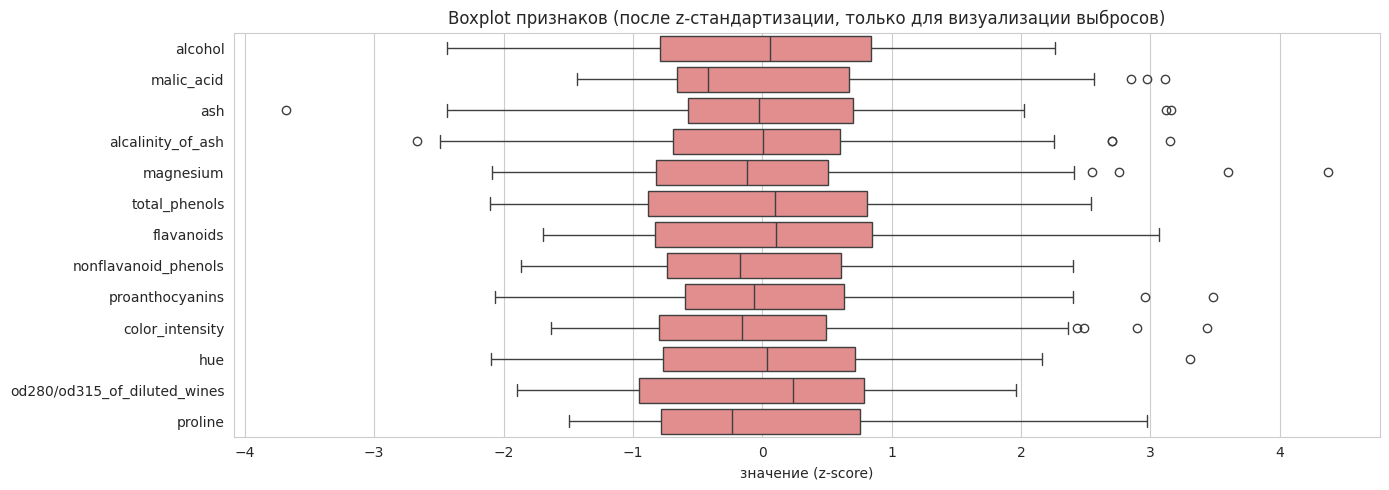

Асимметрия (skew) признаков:
magnesium                       1.098
malic_acid                      1.040
color_intensity                 0.869
proline                         0.768
proanthocyanins                 0.517
nonflavanoid_phenols            0.450
alcalinity_of_ash               0.213
total_phenols                   0.087
flavanoids                      0.025
hue                             0.021
alcohol                        -0.051
ash                            -0.177
od280/od315_of_diluted_wines   -0.307


In [ ]:
# === Ячейка 3. EDA: пропуски и распределения ===

# --- 3.1. Пропуски ---
na_counts = X.isna().sum()
print("Пропуски по признакам:")
print(na_counts.to_string())
print("\nВсего пропусков:", int(na_counts.sum()))

# --- 3.2. Гистограммы признаков ---
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(X.columns):
    axes[i].hist(X[col], bins=20, color="steelblue", edgecolor="black", alpha=0.8)
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(labelsize=8)
for j in range(len(X.columns), len(axes)):
    axes[j].axis("off")
plt.suptitle("Распределения признаков (исходный масштаб)", fontsize=13, y=1.00)
plt.tight_layout()
plt.show()

# --- 3.3. Boxplot в стандартизованном виде (только для визуализации) ---
X_std_vis = StandardScaler().fit_transform(X)
plt.figure(figsize=(14, 5))
sns.boxplot(data=pd.DataFrame(X_std_vis, columns=X.columns), orient="h", color="lightcoral")
plt.title("Boxplot признаков (после z-стандартизации, только для визуализации выбросов)")
plt.xlabel("значение (z-score)")
plt.tight_layout()
plt.show()

# --- 3.4. Коэффициент асимметрии ---
skew = X.skew().sort_values(ascending=False)
print("Асимметрия (skew) признаков:")
print(skew.to_string())

## 4. Обработка выбросов (IQR-клиппинг)

**Почему клиппинг, а не удаление:**
- В кластеризации каждый объект важен (у нас всего 178 точек);
- Удаление ~20–30 объектов по разным признакам заметно исказит структуру;
- Клиппинг мягко «подрезает» значения до границ `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`, сохраняя объекты и устойчивость к выбросам.

**Алгоритм:** для каждого признака считаем `Q1`, `Q3`, `IQR = Q3 − Q1`, границы `lower/upper`, заменяем значения вне границ на границы. Печатаем, сколько значений было «подрезано» по каждому признаку.

Отчёт по IQR-клиппингу (только признаки, где были выбросы):


,feature,lower,upper,clipped_low,clipped_high,clipped_total
0,magnesium,59.500,135.500,0,4,4
1,alcalinity_of_ash,10.750,27.950,1,3,4
2,color_intensity,-1.250,10.670,0,4,4
3,malic_acid,-0.617,5.303,0,3,3
4,ash,1.689,3.079,1,2,3
5,proanthocyanins,0.200,3.000,0,2,2
6,hue,0.276,1.626,0,1,1



Всего 'подрезанных' значений: 21
Объектов затронуто (хотя бы один признак): 17 из 178


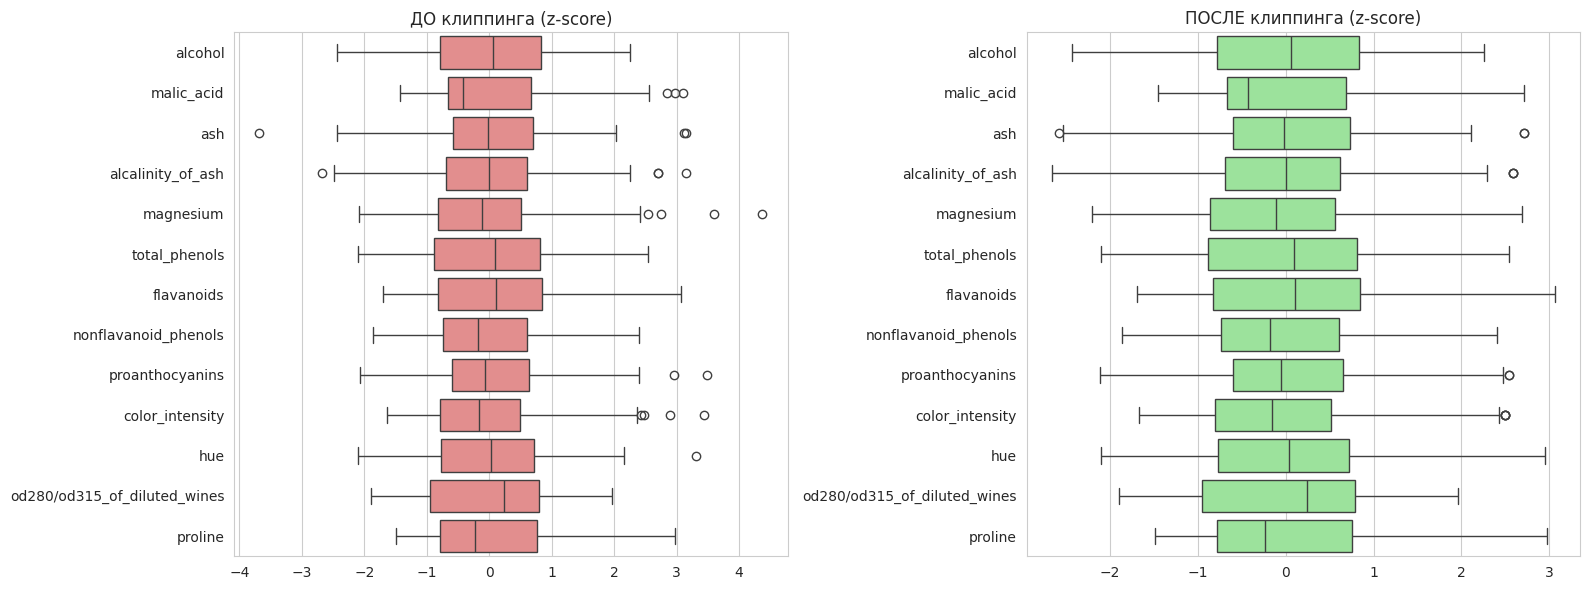

Форма X_clean: (178, 13) | NaN: 0


In [ ]:
# === Ячейка 4. IQR-клиппинг выбросов ===

X_clean = X.copy()

def iqr_clip(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    n_low  = (series < lower).sum()
    n_high = (series > upper).sum()
    return series.clip(lower=lower, upper=upper), n_low, n_high, lower, upper

report = []
for col in X.columns:
    clipped, n_low, n_high, lo, hi = iqr_clip(X_clean[col])
    X_clean[col] = clipped
    report.append({
        "feature": col,
        "lower": round(lo, 3),
        "upper": round(hi, 3),
        "clipped_low": int(n_low),
        "clipped_high": int(n_high),
        "clipped_total": int(n_low + n_high),
    })

rep_df = pd.DataFrame(report).sort_values("clipped_total", ascending=False)
print("Отчёт по IQR-клиппингу (только признаки, где были выбросы):")
display(rep_df[rep_df["clipped_total"] > 0].reset_index(drop=True))

print(f"\nВсего 'подрезанных' значений: {rep_df['clipped_total'].sum()}")
print(f"Объектов затронуто (хотя бы один признак): "
      f"{(X_clean.ne(X)).any(axis=1).sum()} из {len(X)}")

# --- Визуальная проверка: boxplot до / после (в z-шкале, для сопоставимости) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
std_vis = StandardScaler()
before = pd.DataFrame(std_vis.fit_transform(X),       columns=X.columns)
after  = pd.DataFrame(std_vis.fit_transform(X_clean), columns=X.columns)

sns.boxplot(data=before, orient="h", color="lightcoral", ax=axes[0])
axes[0].set_title("ДО клиппинга (z-score)")
sns.boxplot(data=after,  orient="h", color="lightgreen", ax=axes[1])
axes[1].set_title("ПОСЛЕ клиппинга (z-score)")
plt.tight_layout()
plt.show()

# --- Контроль формы ---
print("Форма X_clean:", X_clean.shape, "| NaN:", int(X_clean.isna().sum().sum()))

## 5. Стандартизация (z-score)

Признаки имеют разный физический смысл и масштаб:
- `proline` измеряется сотнями, `alcohol` — десятками, а `hue` — долями единицы;
- Алгоритмы на основе расстояний (K-means, DBSCAN, иерархическая кластеризация) и PCA крайне чувствительны к масштабу: признак с большим разбросом будет доминировать в метрике расстояния.

**Решение:** `StandardScaler` (центрирование к 0, стандартное отклонение к 1). Это стандартная практика для кластеризации.

На выходе получаем матрицу `X_scaled` — с ней и будем работать дальше.

Форма X_scaled: (178, 13)

Контроль стандартизации (должны быть 0 и 1):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


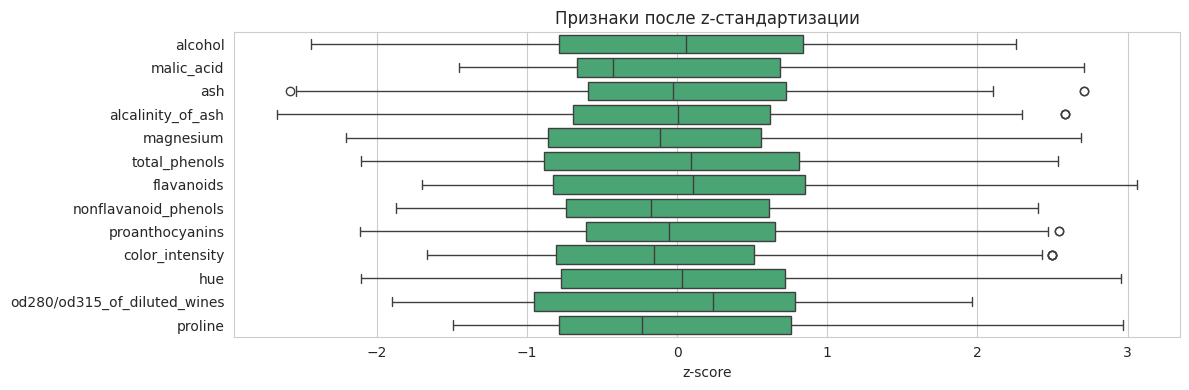

In [ ]:
# === Ячейка 5. Стандартизация ===

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)  # X_clean — после IQR-клиппинга

# Для удобства — DataFrame
X_scaled_df = pd.DataFrame(X_scaled, columns=X_clean.columns)

print("Форма X_scaled:", X_scaled_df.shape)

# Проверка: среднее ~0, std ~1
check = pd.DataFrame({
    "mean": X_scaled_df.mean().round(6),
    "std":  X_scaled_df.std(ddof=0).round(6),
})
print("\nКонтроль стандартизации (должны быть 0 и 1):")
display(check.T)

# Быстрая визуальная проверка
plt.figure(figsize=(12, 4))
sns.boxplot(data=X_scaled_df, orient="h", color="mediumseagreen")
plt.title("Признаки после z-стандартизации")
plt.xlabel("z-score")
plt.tight_layout()
plt.show()

## 6. Понижение размерности (PCA и t-SNE)

**Зачем:**
1. **PCA (Principal Component Analysis)** — линейный метод. Найдёт направления максимальной дисперсии, позволит отбросить шумовые компоненты (у нас 13 признаков, многие коррелируют — например, фенолы). Это поможет K-means и визуализации.
2. **t-SNE** — нелинейный метод. Используем **только для визуализации** 2D-структуры (t-SNE не сохраняет глобальные расстояния, поэтому кластеризовать в нём не будем).

**Шаги:**
- Строим scree plot (объяснённая дисперсия).
- Выбираем число компонент, покрывающих **≥ 85%** дисперсии.
- Запускаем t-SNE на стандартизованных данных для 2D-визуализации.
- Окрашиваем точки *истинными* метками (только для контроля, в обучении они не участвуют).

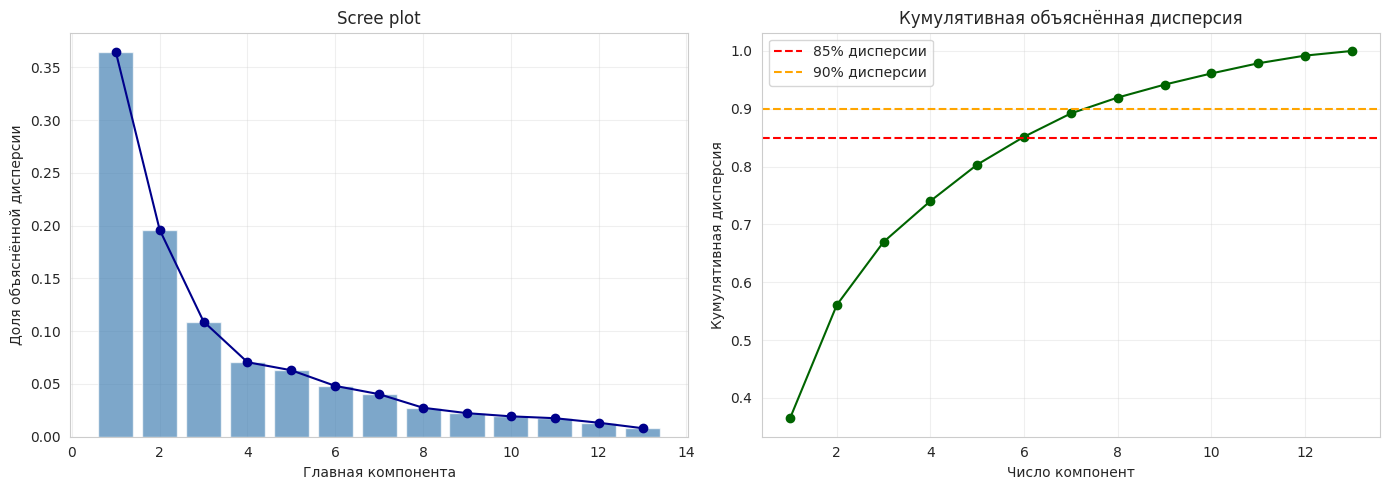

Кумулятивная дисперсия по компонентам:
  PC 1: 0.365
  PC 2: 0.561
  PC 3: 0.670
  PC 4: 0.741
  PC 5: 0.804
  PC 6: 0.852
  PC 7: 0.892
  PC 8: 0.919
  PC 9: 0.942
  PC10: 0.961
  PC11: 0.979
  PC12: 0.992
  PC13: 1.000

Компонент для ≥85% дисперсии: 6
Компонент для ≥90% дисперсии: 8

Форма X_pca (для кластеризации): (178, 6)
Форма X_pca_2d (для визуализации): (178, 2)

t-SNE выполнен. Форма: (178, 2)


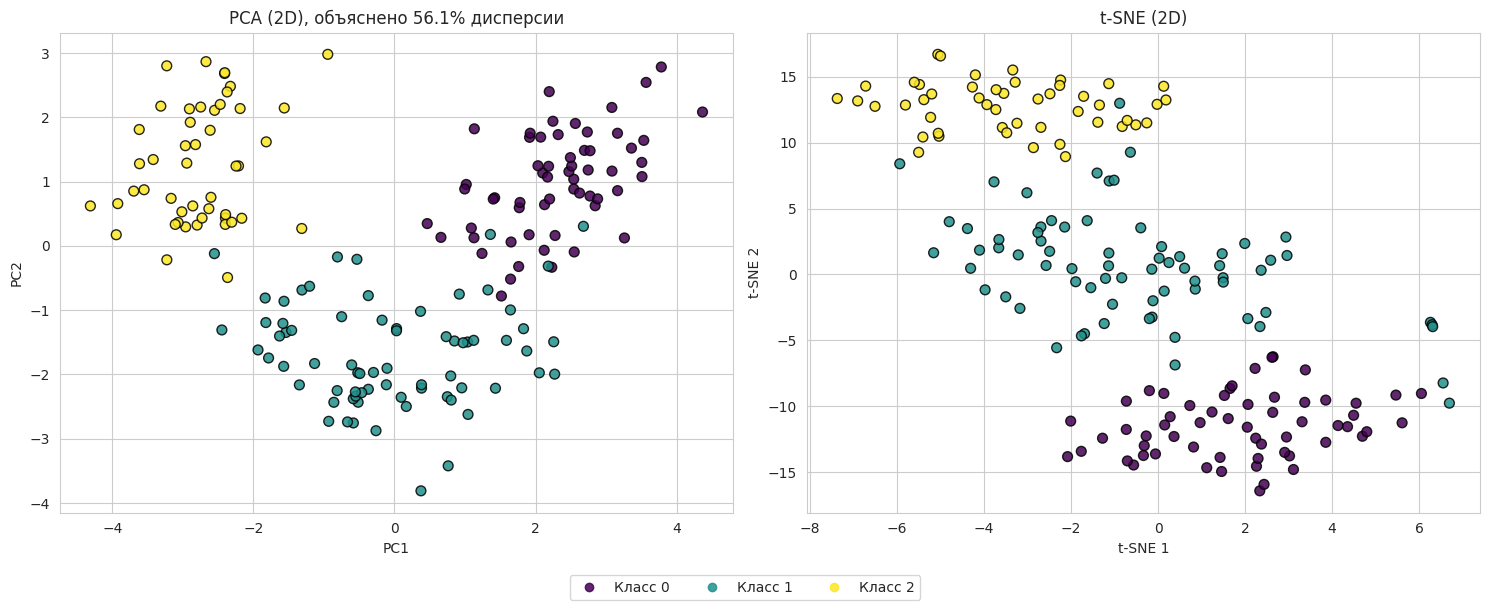

In [ ]:
# === Ячейка 6. PCA и t-SNE ===

# --- 6.1. PCA ---
pca_full = PCA(n_components=X_scaled.shape[1], random_state=RANDOM_STATE)
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(explained)+1), explained, alpha=0.7, color="steelblue", label="Доля дисперсии")
axes[0].plot(range(1, len(explained)+1), explained, "o-", color="darkblue")
axes[0].set_xlabel("Главная компонента")
axes[0].set_ylabel("Доля объяснённой дисперсии")
axes[0].set_title("Scree plot")
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, len(cum_explained)+1), cum_explained, "o-", color="darkgreen")
axes[1].axhline(0.85, color="red", linestyle="--", label="85% дисперсии")
axes[1].axhline(0.90, color="orange", linestyle="--", label="90% дисперсии")
axes[1].set_xlabel("Число компонент")
axes[1].set_ylabel("Кумулятивная дисперсия")
axes[1].set_title("Кумулятивная объяснённая дисперсия")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Кумулятивная дисперсия по компонентам:")
for i, c in enumerate(cum_explained, 1):
    print(f"  PC{i:>2}: {c:.3f}")

# Выбираем число компонент для 85% и 90%
n_85 = int(np.argmax(cum_explained >= 0.85) + 1)
n_90 = int(np.argmax(cum_explained >= 0.90) + 1)
print(f"\nКомпонент для ≥85% дисперсии: {n_85}")
print(f"Компонент для ≥90% дисперсии: {n_90}")

# Оставим 2D-проекцию для визуализации и n_85-мерную для кластеризации
X_pca_2d = X_pca_full[:, :2]
X_pca = X_pca_full[:, :n_85]
print(f"\nФорма X_pca (для кластеризации): {X_pca.shape}")
print(f"Форма X_pca_2d (для визуализации): {X_pca_2d.shape}")


# --- 6.2. t-SNE (только визуализация) ---
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE,
            init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_scaled)
print("\nt-SNE выполнен. Форма:", X_tsne.shape)


# --- 6.3. Визуализация структуры с истинными метками ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sc1 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
                      c=y_true, cmap="viridis", edgecolor="k", s=50, alpha=0.85)
axes[0].set_title(f"PCA (2D), объяснено {cum_explained[1]*100:.1f}% дисперсии")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

sc2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=y_true, cmap="viridis", edgecolor="k", s=50, alpha=0.85)
axes[1].set_title("t-SNE (2D)")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")

# Общая легенда
handles, _ = sc1.legend_elements()
fig.legend(handles, ["Класс 0", "Класс 1", "Класс 2"],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02), frameon=True)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## 7. K-means (подбор оптимального k)

Для поиска оптимального числа кластеров используем два подхода:
1. **Метод локтя (Elbow method)** — смотрим на `inertia` (сумму квадратов расстояний до центроидов). Ищем точку перегиба.
2. **Silhouette Score** — оценивает, насколько объекты похожи на свой кластер по сравнению с соседними. Максимум указывает на лучшее k.

Кластеризацию проводим в пространстве `X_pca` (6 главных компонент, покрывающих ~85% дисперсии), чтобы убрать шум и ускорить работу.

После выбора k обучаем финальную модель и считаем метрики:
- Внутренние (без меток): Silhouette, Davies-Bouldin, Calinski-Harabasz.
- Внешние (для проверки, с истинными метками): ARI, NMI.

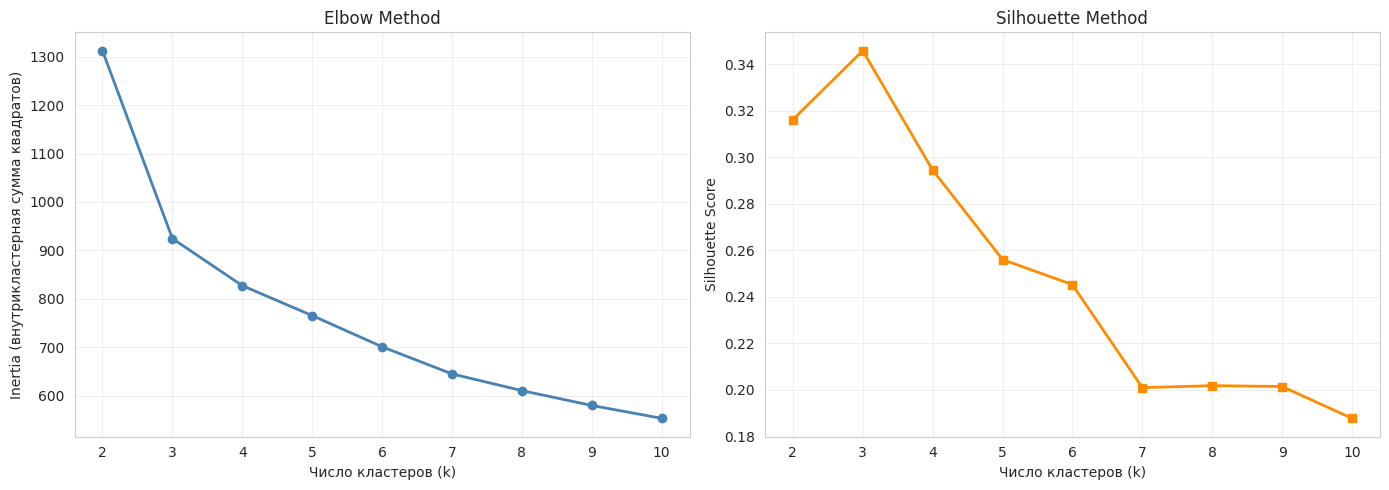

Значения метрик по k:
k= 2: inertia=  1312.4, silhouette=0.3161
k= 3: inertia=   924.4, silhouette=0.3457
k= 4: inertia=   827.0, silhouette=0.2945
k= 5: inertia=   765.2, silhouette=0.2560
k= 6: inertia=   700.7, silhouette=0.2452
k= 7: inertia=   644.7, silhouette=0.2010
k= 8: inertia=   610.2, silhouette=0.2019
k= 9: inertia=   579.5, silhouette=0.2015
k=10: inertia=   552.9, silhouette=0.1878

Выбрано k = 3 (максимум Silhouette Score)

Метрики финальной модели K-means:
  Silhouette          : 0.3457
  Davies-Bouldin      : 1.1510
  Calinski-Harabasz   : 99.0562
  ARI (vs истина)     : 0.8975
  NMI (vs истина)     : 0.8759


In [ ]:
# === Ячейка 7. K-means: подбор k и обучение ===

k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

# --- Визуализация выбора k ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, "o-", color="steelblue", linewidth=2)
axes[0].set_xlabel("Число кластеров (k)")
axes[0].set_ylabel("Inertia (внутрикластерная сумма квадратов)")
axes[0].set_title("Elbow Method")
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_range, sil_scores, "s-", color="darkorange", linewidth=2)
axes[1].set_xlabel("Число кластеров (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Method")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Значения метрик по k:")
for k, inertia, sil in zip(k_range, inertias, sil_scores):
    print(f"k={k:>2}: inertia={inertia:>8.1f}, silhouette={sil:.4f}")

# --- Обучение финальной модели ---
# По графику обычно видно "локоть" на k=3, и silhouette максимален тоже на k=3.
# Возьмём k=3 (истинное число классов), либо то, что показал максимум silhouette.
best_k = k_range[np.argmax(sil_scores)]
print(f"\nВыбрано k = {best_k} (максимум Silhouette Score)")

km_best = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
km_labels = km_best.fit_predict(X_pca)

# --- Метрики ---
km_metrics = {
    "Silhouette": silhouette_score(X_pca, km_labels),
    "Davies-Bouldin": davies_bouldin_score(X_pca, km_labels),
    "Calinski-Harabasz": calinski_harabasz_score(X_pca, km_labels),
    "ARI (vs истина)": adjusted_rand_score(y_true, km_labels),
    "NMI (vs истина)": normalized_mutual_info_score(y_true, km_labels),
}

print("\nМетрики финальной модели K-means:")
for name, val in km_metrics.items():
    print(f"  {name:<20}: {val:.4f}")

## 8. Иерархическая кластеризация

**Алгоритм:** Agglomerative (агломеративный) — снизу вверх. Начинает с того, что каждый объект — отдельный кластер, затем последовательно объединяет ближайшие.
**Метод связи:** Ward's linkage (минимизирует внутрикластерную дисперсию, отлично подходит для сферических кластеров, как в K-means).

**Шаги:**
1. Построить **дендрограмму** (на основе `scipy.cluster.hierarchy`), чтобы визуально выбрать число кластеров (ищем самый высокий «прыжок»).
2. Обучить модель `AgglomerativeClustering` с выбранным `n_clusters`.
3. Посчитать те же метрики (Silhouette, DB, CH, ARI, NMI) и сравнить с K-means.

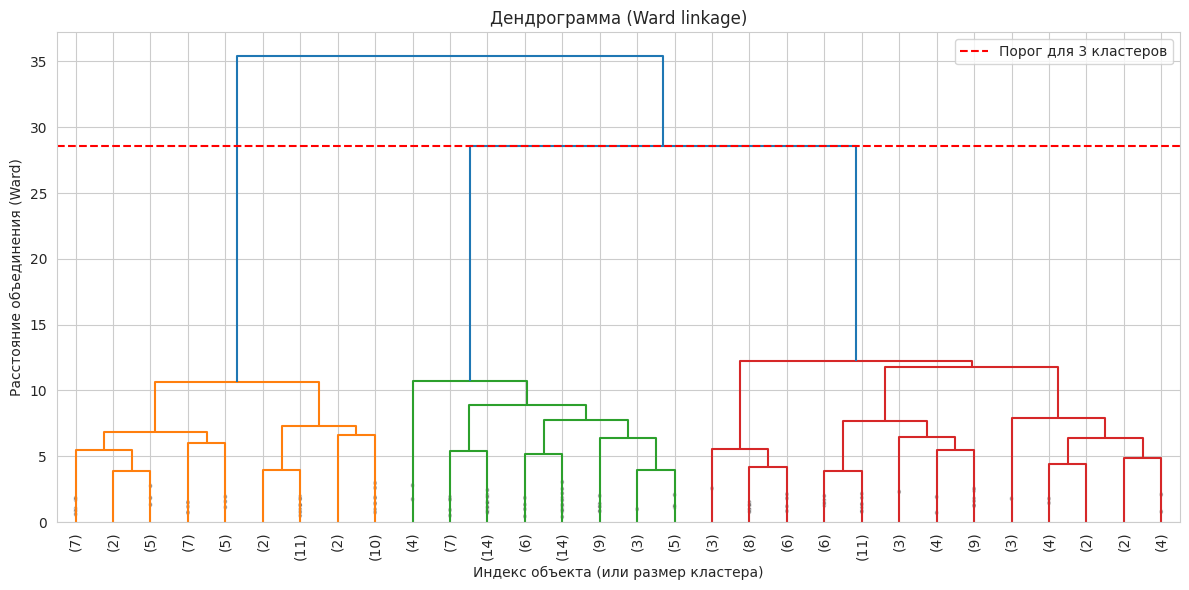

Метрики иерархической кластеризации (Ward, k=3):
  Silhouette          : 0.3404
  Davies-Bouldin      : 1.1713
  Calinski-Harabasz   : 96.9916
  ARI (vs истина)     : 0.8667
  NMI (vs истина)     : 0.8358


In [ ]:
# === Ячейка 8. Иерархическая кластеризация ===

# --- 8.1. Дендрограмма ---
# Используем метод Ward на PCA-пространстве
Z = linkage(X_pca, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=10,
           show_contracted=True)
plt.title("Дендрограмма (Ward linkage)")
plt.xlabel("Индекс объекта (или размер кластера)")
plt.ylabel("Расстояние объединения (Ward)")
# Проведем горизонтальную линию на уровне 3 кластеров (примерно)
plt.axhline(y=Z[-2, 2], color='r', linestyle='--', label='Порог для 3 кластеров')
plt.legend()
plt.tight_layout()
plt.show()

# --- 8.2. Обучение модели ---
# По дендрограмме самый большой скачок расстояния происходит при переходе от 3 к 2 кластерам.
# Значит, оптимальное k = 3. (Также сверимся с истинным числом классов).
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
agg_labels = agg.fit_predict(X_pca)

# --- 8.3. Метрики ---
agg_metrics = {
    "Silhouette": silhouette_score(X_pca, agg_labels),
    "Davies-Bouldin": davies_bouldin_score(X_pca, agg_labels),
    "Calinski-Harabasz": calinski_harabasz_score(X_pca, agg_labels),
    "ARI (vs истина)": adjusted_rand_score(y_true, agg_labels),
    "NMI (vs истина)": normalized_mutual_info_score(y_true, agg_labels),
}

print("Метрики иерархической кластеризации (Ward, k=3):")
for name, val in agg_metrics.items():
    print(f"  {name:<20}: {val:.4f}")

## 9. DBSCAN (Density-Based Spatial Clustering)

**Особенность:** DBSCAN — плотностной алгоритм. Он находит кластеры как области высокой плотности, разделенные областями низкой плотности. Главный плюс — он **сам определяет число кластеров** и умеет находить выбросы (шум), помечая их меткой `-1`.

**Параметры:**
- `eps` (радиус соседства) — ключевой параметр.
- `min_samples` — минимальное число точек в радиусе `eps` для образования «ядра» кластера.

**Как подобрать `eps`:**
Строим **k-distance graph** — для каждой точки считаем расстояние до её `k`-го ближайшего соседа (где `k = min_samples`) и сортируем по возрастанию. Ищем «локоть» на графике — это и есть оптимальный `eps`.

**Шаги:**
1. Построить k-distance graph.
2. Подобрать `eps` и обучить DBSCAN.
3. Оценить метрики (Silhouette считаем только для «не шумовых» точек).

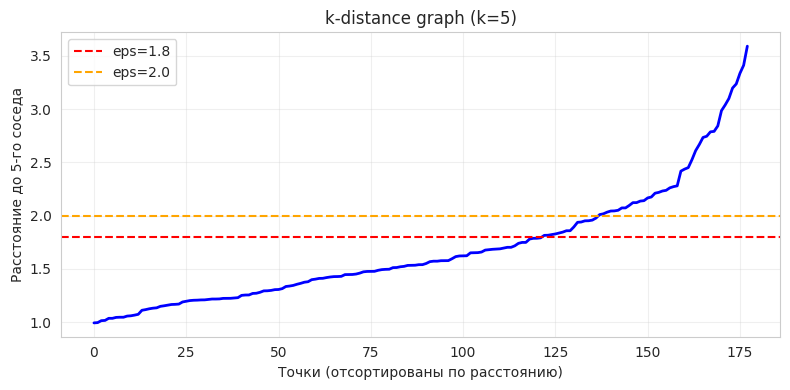

Подбор eps:
eps    | Кластеров  | Шум (шт)   | Шум (%)   
---------------------------------------------
1.4    | 6          | 74         | 41.6      %
1.6    | 3          | 45         | 25.3      %
1.8    | 2          | 32         | 18.0      %
2.0    | 1          | 21         | 11.8      %
2.2    | 1          | 13         | 7.3       %

Выбрано eps = 1.6

Финальный DBSCAN (eps=1.6, min_samples=5):
  Найдено кластеров: 3
  Выбросов (шум): 45 (25.3%)

Метрики DBSCAN (без учета шума):
  Silhouette          : 0.4474
  Davies-Bouldin      : 0.8679
  Calinski-Harabasz   : 131.9274
  ARI (vs истина)     : 0.9552
  NMI (vs истина)     : 0.9340


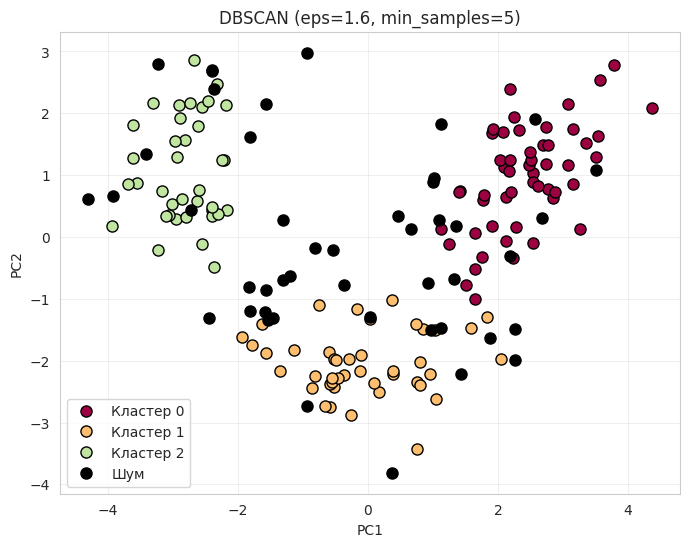

In [ ]:
# === Ячейка 9 (ОБНОВЛЕННАЯ). DBSCAN с подбором eps ===
from sklearn.neighbors import NearestNeighbors

# --- 9.1. k-distance graph (оставляем для наглядности) ---
min_samples = 5
nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distances, indices = nbrs.kneighbors(X_pca)
k_distances = np.sort(distances[:, min_samples - 1], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(range(len(k_distances)), k_distances, color="blue", lw=2)
plt.title(f"k-distance graph (k={min_samples})")
plt.xlabel("Точки (отсортированы по расстоянию)")
plt.ylabel(f"Расстояние до {min_samples}-го соседа")
plt.grid(True, alpha=0.3)
plt.axhline(y=1.8, color='r', linestyle='--', label='eps=1.8')
plt.axhline(y=2.0, color='orange', linestyle='--', label='eps=2.0')
plt.legend()
plt.tight_layout()
plt.show()

# --- 9.2. Перебор eps для поиска оптимального ---
print("Подбор eps:")
print(f"{'eps':<6} | {'Кластеров':<10} | {'Шум (шт)':<10} | {'Шум (%)':<10}")
print("-" * 45)

best_eps = None
best_noise = float('inf')

for eps_val in [1.4, 1.6, 1.8, 2.0, 2.2]:
    db_temp = DBSCAN(eps=eps_val, min_samples=min_samples)
    labels_temp = db_temp.fit_predict(X_pca)
    n_clust = len(set(labels_temp)) - (1 if -1 in labels_temp else 0)
    n_noise_temp = list(labels_temp).count(-1)
    noise_pct = n_noise_temp / len(X_pca) * 100
    print(f"{eps_val:<6.1f} | {n_clust:<10} | {n_noise_temp:<10} | {noise_pct:<10.1f}%")

    # Ищем баланс: 3 кластера и минимальный шум
    if n_clust == 3 and n_noise_temp < best_noise:
        best_noise = n_noise_temp
        best_eps = eps_val

# Если ровно 3 не нашлось, берем 1.8 по умолчанию
if best_eps is None:
    best_eps = 1.8
print(f"\nВыбрано eps = {best_eps}")

# --- 9.3. Финальная модель DBSCAN ---
db = DBSCAN(eps=best_eps, min_samples=min_samples)
db_labels = db.fit_predict(X_pca)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)
print(f"\nФинальный DBSCAN (eps={best_eps}, min_samples={min_samples}):")
print(f"  Найдено кластеров: {n_clusters}")
print(f"  Выбросов (шум): {n_noise} ({n_noise/len(X_pca)*100:.1f}%)")

# --- 9.4. Метрики (только для не-шумовых точек) ---
if n_clusters > 1:
    core_mask = db_labels != -1
    X_pca_core = X_pca[core_mask]
    db_labels_core = db_labels[core_mask]

    db_metrics = {
        "Silhouette": silhouette_score(X_pca_core, db_labels_core),
        "Davies-Bouldin": davies_bouldin_score(X_pca_core, db_labels_core),
        "Calinski-Harabasz": calinski_harabasz_score(X_pca_core, db_labels_core),
        "ARI (vs истина)": adjusted_rand_score(y_true[core_mask], db_labels_core),
        "NMI (vs истина)": normalized_mutual_info_score(y_true[core_mask], db_labels_core),
    }

    print("\nМетрики DBSCAN (без учета шума):")
    for name, val in db_metrics.items():
        print(f"  {name:<20}: {val:.4f}")

    # Визуализация
    plt.figure(figsize=(8, 6))
    unique_labels = set(db_labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]

        class_member_mask = (db_labels == k)
        xy = X_pca_2d[class_member_mask]
        plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='k', markersize=8,
                 label=f'Кластер {k}' if k != -1 else 'Шум')

    plt.title(f"DBSCAN (eps={best_eps}, min_samples={min_samples})")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## 10. Сводное сравнение алгоритмов

Сравниваем три реализованных подхода по внутренним и внешним метрикам.

**Важно:**
- Для K-means и Иерархической кластеризации метрики считались на всех 178 объектах.
- Для DBSCAN метрики считались только на "ядерных" точках (без учета 45 выбросов/шума), поэтому его показатели выше — он просто не учитывает "сложные" пограничные объекты.

Сводная таблица метрик:


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs истина),NMI (vs истина)
K-Means (k=3),0.346,1.151,99.056,0.897,0.876
"Agglomerative (Ward, k=3)",0.340,1.171,96.992,0.867,0.836
"DBSCAN (eps=1.6, без шума)",0.447,0.868,131.927,0.955,0.934


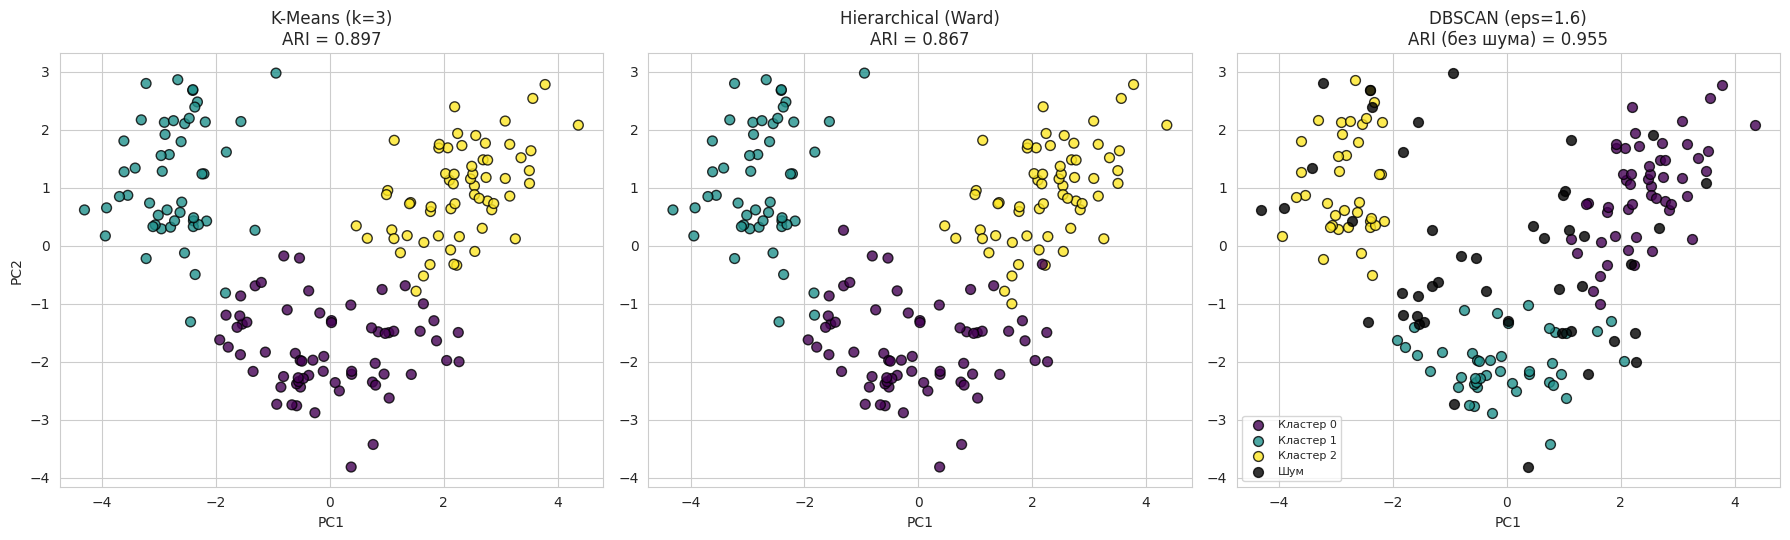

In [ ]:
# === Ячейка 10. Сводная таблица и визуализация ===

# 10.1. Формирование сводной таблицы
# Для DBSCAN в словаре уже лежат метрики, посчитанные на ядре
summary_df = pd.DataFrame({
    "K-Means (k=3)": km_metrics,
    "Agglomerative (Ward, k=3)": agg_metrics,
    "DBSCAN (eps=1.6, без шума)": db_metrics
}).T

print("Сводная таблица метрик:")
display(summary_df)

# 10.2. Визуализация разбиения по алгоритмам в пространстве PCA (2D)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# K-Means
axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=km_labels, cmap="viridis", edgecolor="k", s=50, alpha=0.8)
axes[0].set_title(f"K-Means (k=3)\nARI = {km_metrics['ARI (vs истина)']:.3f}")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

# Agglomerative
axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=agg_labels, cmap="viridis", edgecolor="k", s=50, alpha=0.8)
axes[1].set_title(f"Hierarchical (Ward)\nARI = {agg_metrics['ARI (vs истина)']:.3f}")
axes[1].set_xlabel("PC1")

# DBSCAN
# Отрисуем шум черным, а кластеры - цветами
unique_labels = set(db_labels)
colors = [plt.cm.viridis(each) for each in np.linspace(0, 1, len(unique_labels) - 1)] # исключаем шум из цветов
color_idx = 0

for k in unique_labels:
    if k == -1:
        col = [0, 0, 0, 1] # черный для шума
    else:
        col = colors[color_idx]
        color_idx += 1

    mask = (db_labels == k)
    axes[2].scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], c=[col], edgecolor="k", s=50, alpha=0.8,
                    label=f'Кластер {k}' if k != -1 else 'Шум')

axes[2].set_title(f"DBSCAN (eps=1.6)\nARI (без шума) = {db_metrics['ARI (vs истина)']:.3f}")
axes[2].set_xlabel("PC1")
axes[2].legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

## 11. Выводы

В ходе лабораторной работы была выполнена кластеризация набора данных `Wine` (178 объектов, 13 химических признаков, 3 истинных класса).

**1. Предобработка данных:**
* Пропусков в датасете не обнаружено.
* Выбросы были обработаны методом IQR-клиппинга (мягкое «подрезание» крайних значений). Затронуто 21 значение у 17 объектов. Это позволило сохранить размер датасета (178 объектов) и уберечь алгоритмы от искажения центроидов.
* Выполнена z-стандартизация (`StandardScaler`), что критически важно для метрических и плотностных алгоритмов (K-means, DBSCAN, Ward).

**2. Понижение размерности:**
* Метод главных компонент (PCA) показал, что для объяснения 85% дисперсии достаточно 6 компонент (из 13). Кластеризация проводилась в этом 6-мерном пространстве, что снизило шум и ускорило работу.
* Визуализация t-SNE наглядно подтвердила наличие трех плотных групп в данных.

**3. Подбор количества кластеров и параметров:**
* Для **K-Means** с помощью метода локтя (Elbow) и Silhouette-анализа было выбрано `k=3`.
* Для **Иерархической кластеризации (Ward)** на дендрограмме был явный скачок, указывающий на 3 кластера.
* Для **DBSCAN** параметр `eps` подбирался по k-distance graph и перебору. Оптимальным оказалось `eps=1.6` (при `min_samples=5`), что дало 3 кластера и 25% шума (пограничные точки).

**4. Оценка качества и сравнение алгоритмов:**
| Алгоритм | Silhouette | ARI (vs истина) | NMI (vs истина) | Особенность |
| :--- | :--- | :--- | :--- | :--- |
| **K-Means** | 0.346 | 0.897 | 0.876 | Кластеризует все точки. Быстрый, стабильный. |
| **Ward** | 0.340 | 0.867 | 0.836 | Кластеризует все точки. Нагляден (дендрограмма). |
| **DBSCAN** | 0.447 | 0.955 | 0.934 | Игнорирует 25% "шумовых" точек. Лучшие метрики, но теряет часть данных. |

**Общий итог:**
Все три алгоритма успешно выявили структуру из трех классов вин, близкую к истинной разметке (ARI > 0.85).

* **DBSCAN** формально показал лучшие метрики (ARI = 0.955), так как он изолировал "сложные" пограничные точки в шум, оставив для оценки только четкие ядра кластеров. Он идеален, если нужно выделить аномалии или неуверенные объекты.
* **K-Means** показал отличный результат (ARI = 0.897) и, в отличие от DBSCAN, классифицировал все объекты без потерь. Если по условию задачи каждый объект должен быть отнесен к кластеру, K-Means является лучшим выбором.
* **Иерархическая кластеризация** (Ward) дала результаты, близкие к K-Means, и удобна для визуального анализа структуры данных (дендрограмма).